### Task 1: Multi-class benchmark classification pipeline (Iris)

In [1]:
### Import the libraries 

import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
plt.switch_backend("module://matplotlib_inline.backend_inline")
print("Backend:", matplotlib.get_backend())
from IPython.display import Image, display
from IPython.display import Image as IPImage, display
 
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)
from sklearn.inspection import DecisionBoundaryDisplay
 
SEED = 42
OUT = "outputs"
os.makedirs(OUT, exist_ok=True)

Backend: module://matplotlib_inline.backend_inline


In [2]:
### Load the dataset 


if os.path.exists("iris.csv"):
    iris_df = pd.read_csv("iris.csv")
else:
    raw = load_iris(as_frame=True)
    iris_df = raw.frame.rename(columns={
        "sepal length (cm)": "sepal_length", "sepal width (cm)": "sepal_width",
        "petal length (cm)": "petal_length", "petal width (cm)": "petal_width"})
    iris_df["species"] = raw.target.map(dict(enumerate(raw.target_names)))
    

In [3]:
def show_fig(fig, filename):
    path = f"{OUT}/{filename}"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.close(fig)
    display(IPImage(filename=path))

In [4]:
iris_df = iris_df.drop(columns="target")

In [5]:
iris_df.shape

(150, 5)

In [6]:
iris_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


In [7]:
iris_df.isnull().sum()

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

In [8]:
iris_df.duplicated()

0      False
1      False
2      False
3      False
4      False
       ...  
145    False
146    False
147    False
148    False
149    False
Length: 150, dtype: bool

In [9]:
print("Duplicate rows:", int(iris_df.duplicated().sum()))

Duplicate rows: 1


In [10]:
iris_df["species"].value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

In [11]:
iris_df.value_counts()

sepal_length  sepal_width  petal_length  petal_width  species  
5.8           2.7          5.1           1.9          virginica    2
4.4           2.9          1.4           0.2          setosa       1
              3.0          1.3           0.2          setosa       1
              3.2          1.3           0.2          setosa       1
4.3           3.0          1.1           0.1          setosa       1
                                                                  ..
7.7           2.6          6.9           2.3          virginica    1
              2.8          6.7           2.0          virginica    1
              3.0          6.1           2.3          virginica    1
              3.8          6.7           2.2          virginica    1
7.9           3.8          6.4           2.0          virginica    1
Name: count, Length: 149, dtype: int64

In [12]:
features = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
X, y = iris_df[features], iris_df["species"]
labels = sorted(y.unique())

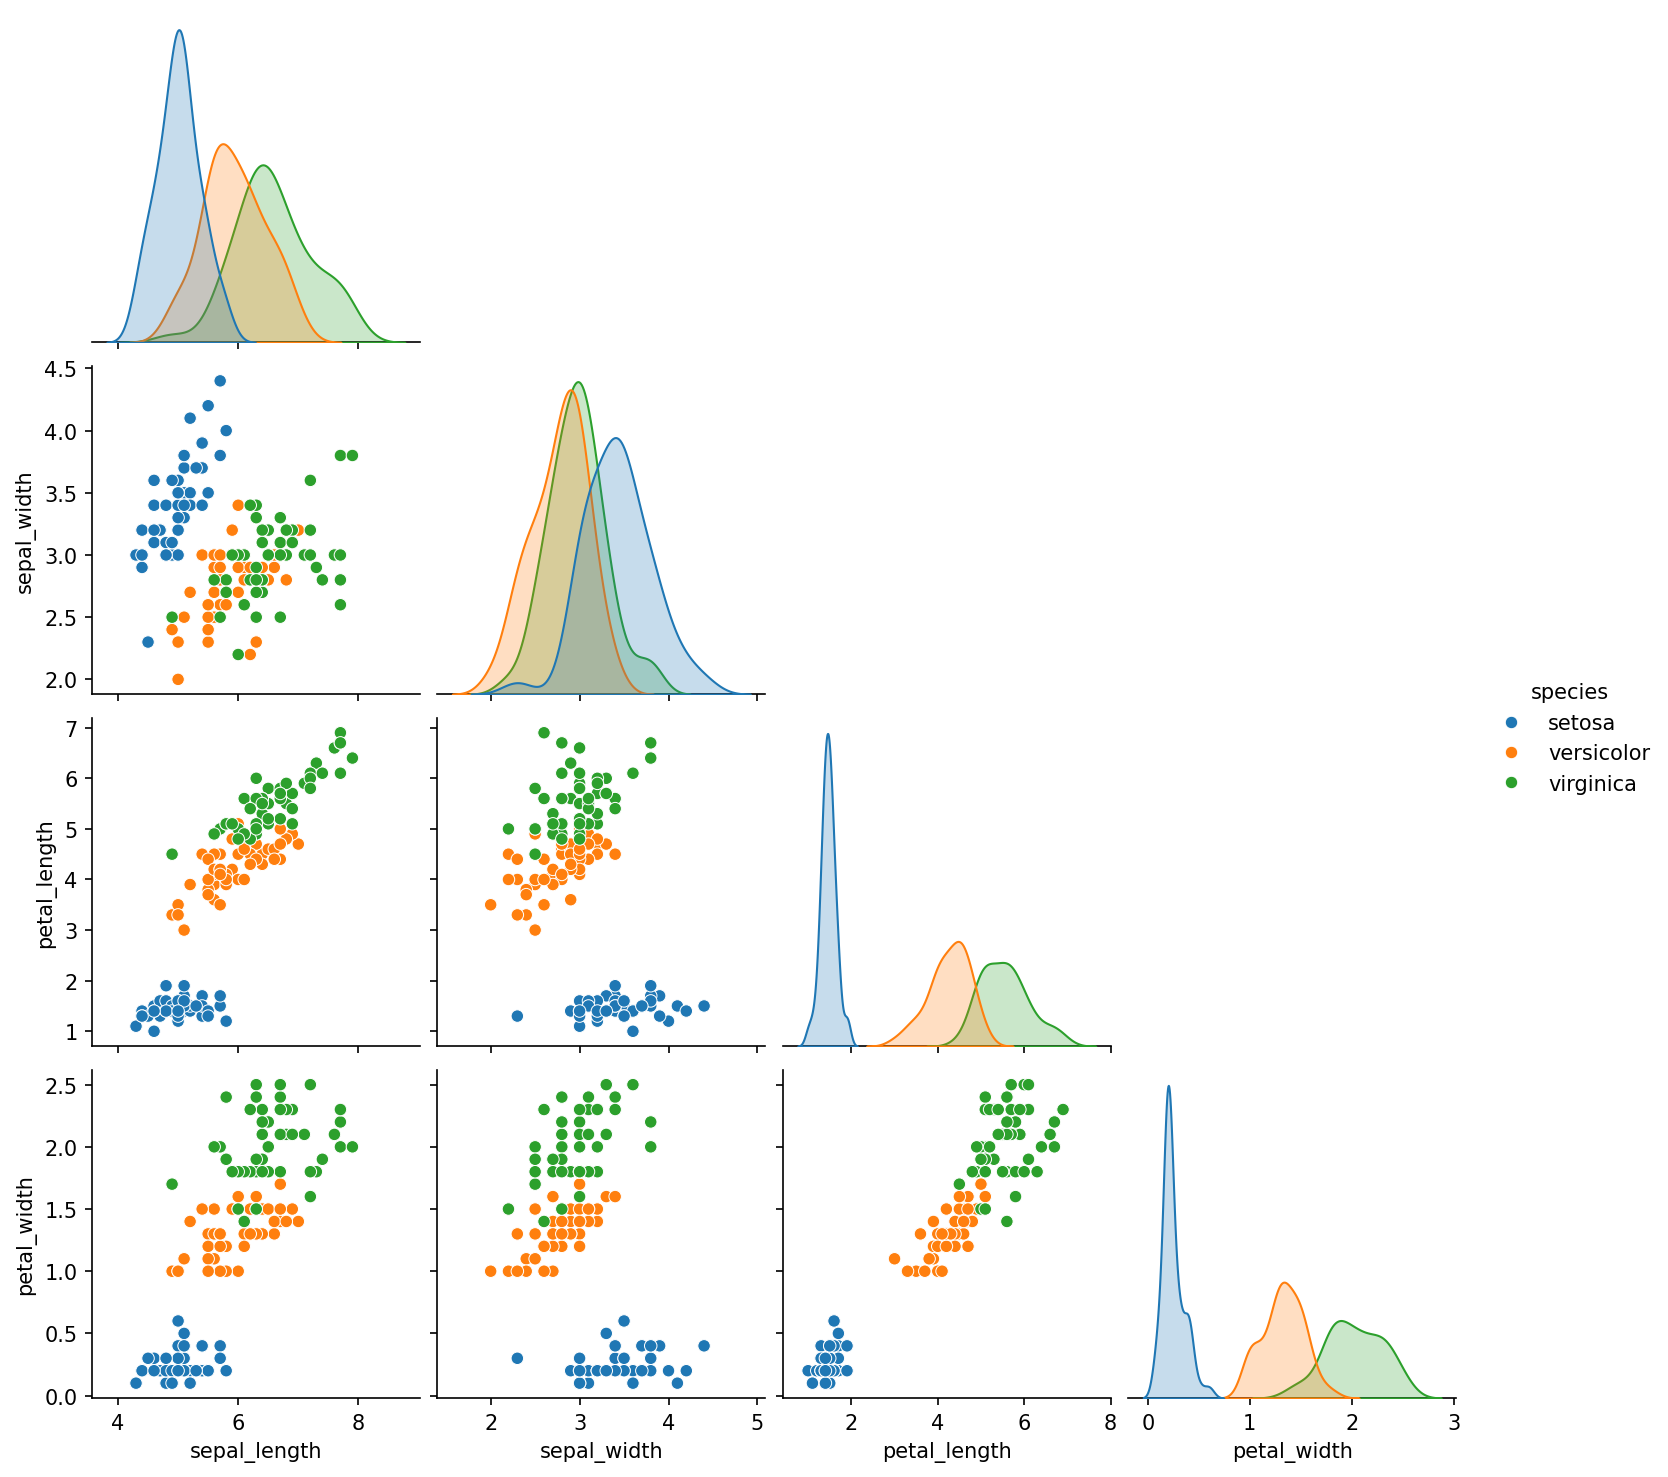

In [13]:
g = sns.pairplot(iris_df, hue="species", corner=True)
g.savefig(f"{OUT}/01_pairplot.png", dpi=150, bbox_inches="tight")
plt.close(g.figure)
display(IPImage(filename=f"{OUT}/01_pairplot.png"))

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

In [15]:
plt.close("all")

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Decision Tree": make_pipeline(StandardScaler(), DecisionTreeClassifier(random_state=SEED)),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rows, preds = [], {}
for name, model in models.items():
    model.fit(X_train, y_train)
    preds[name] = model.predict(X_test)
    p, r, f1, _ = precision_recall_fscore_support(
        y_test, preds[name], average="macro", zero_division=0)
    cv_scores = cross_val_score(model, X, y, cv=cv)
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, preds[name]),
                 "Precision (macro)": p, "Recall (macro)": r, "F1 (macro)": f1,
                 "CV acc mean": cv_scores.mean(), "CV acc std": cv_scores.std()})
    print(f"=== {name} ===")
    print(classification_report(y_test, preds[name], zero_division=0))

=== Logistic Regression ===
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

=== Decision Tree ===
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [16]:
# Results table
results = pd.DataFrame(rows).round(3)
display(results)
results.to_csv(f"{OUT}/results.csv", index=False)

,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro),CV acc mean,CV acc std
0,Logistic Regression,0.933,0.933,0.933,0.933,0.953,0.045
1,Decision Tree,0.933,0.933,0.933,0.933,0.953,0.034


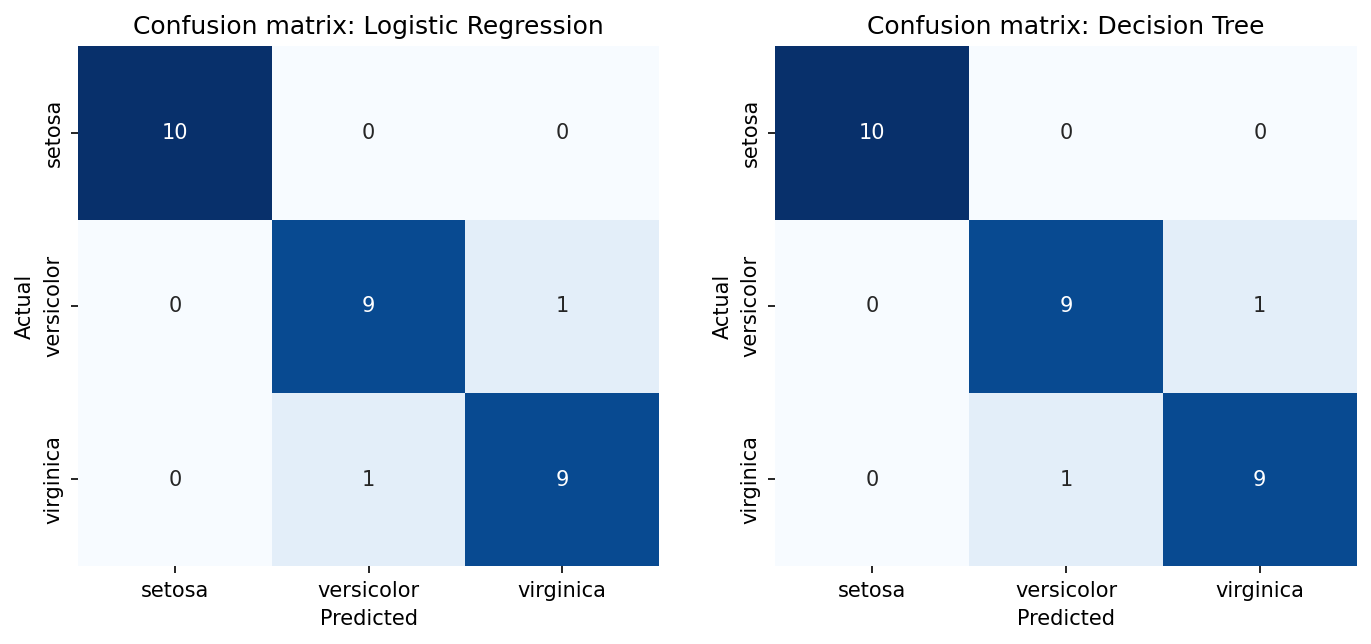

In [17]:
labels = sorted(y.unique())

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, pred) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, pred, labels=labels)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set_title(f"Confusion matrix: {name}")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")

fig.savefig(f"{OUT}/02_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.close(fig)
display(IPImage(filename=f"{OUT}/02_confusion_matrices.png"))

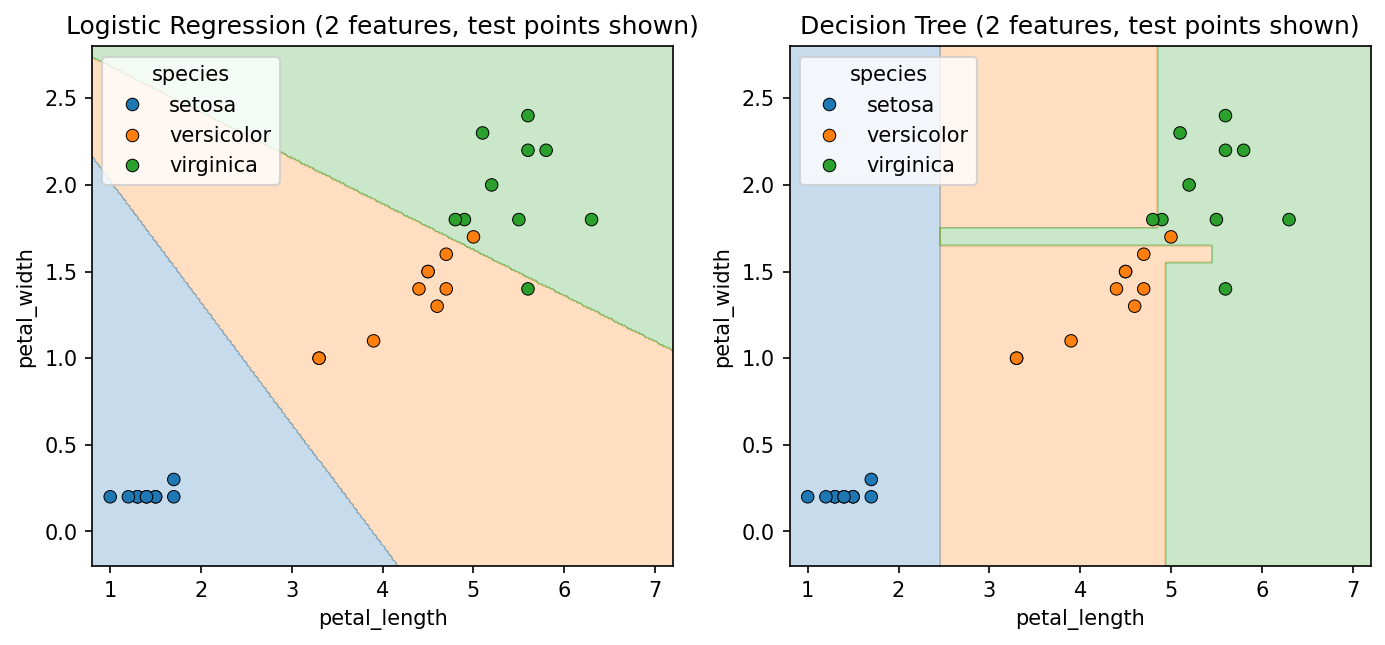

In [18]:
from matplotlib.colors import ListedColormap

colors = sns.color_palette(n_colors=3)      # same blue/orange/green as the pairplot
cmap = ListedColormap(colors)
pair = ["petal_length", "petal_width"]
y_num_train = y_train.map({c: i for i, c in enumerate(labels)})

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, clf) in zip(axes, {
        "Logistic Regression": LogisticRegression(max_iter=1000),
        "Decision Tree": DecisionTreeClassifier(random_state=SEED)}.items()):
    pipe = make_pipeline(StandardScaler(), clf).fit(X_train[pair], y_num_train)
    DecisionBoundaryDisplay.from_estimator(
        pipe, X_train[pair], response_method="predict",
        cmap=cmap, alpha=0.25, ax=ax, grid_resolution=300, eps=0.3)
    sns.scatterplot(x=X_test[pair[0]], y=X_test[pair[1]], hue=y_test,
                    hue_order=labels, palette=colors, ax=ax, edgecolor="k")
    ax.set_title(f"{name} (2 features, test points shown)")

show_fig(fig, "03_decision_boundaries.png")